# Parkinson's pose-estimation clinical assessments — Instructor EDA

## What is this dataset?

2D CPM body trajectories from communication, drinking, and leg-agility clinical tasks. The official archive links trials to UPDRS, UDysRS, and CAPSIT ratings; original scene video is absent from the downloaded archive.

This notebook follows the supplied CARE-PD example's presentation flow: setup, load, overview, duration, scores, clinical context, individual motion, animation, and final summary. It uses **this original source's actual format and fields**, not CARE-PD's derived SMPL representation.

**Evidence scope:** The public plots use verified aggregate results in `docs/presentation_data.json`. Motion figures and three MP4s display only when generated locally by `notebooks/eda_parkinsons_pose.ipynb`. They are not included in the public repository. No classifier is trained or synthetic patient trajectory created.


---
## 1. Setup

Open from the repository root or its `notebooks/` directory. Sections using public aggregate data work without the original archives. Run the detailed source notebook locally first for the motion gallery and videos.


In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Video

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'docs' / 'presentation_data.json').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Run from the repository root or notebooks/ directory.')
DATA = json.loads((ROOT / 'docs' / 'presentation_data.json').read_text(encoding='utf-8'))
KEY, SLUG = 'Clinical pose', 'pose_estimation'
COLOR = {'MMU': '#3268a8', 'BMCLab': '#e08035', 'Clinical pose': '#2a9d8f'}[KEY]
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print('Aggregate snapshot:', DATA['as_of'])
print('Source:', KEY)


Aggregate snapshot: 2026-10-18
Source: Clinical pose


---
## 2. Load and understand the source

The 643 full-body pose entries comprise 387 communication, 124 drinking, and 132 leg-agility trajectories. A separate toe-tapping file contains optical flow, not a full-body skeleton. The trial map contains nine distinct subject IDs. The three displayed pose examples come from communication and drinking.

The detailed source notebook documents the actual loader, coordinate mapping, frame IDs, and per-recording checks. This presentation reads a small aggregate snapshot so it remains runnable in the public repository.


In [2]:
info = pd.Series(next(x for x in DATA['overview'] if x['dataset'] == KEY), name='value')
display(info.to_frame())
quality = pd.Series(DATA['selected_quality'][KEY], name='value')
print('Selected-example quality summary:')
display(quality.to_frame())


,value
dataset,Clinical pose
modality,2D CPM trajectories
participants,9
participant_note,distinct IDs in trial map
recordings,643
recording_unit,pose trajectories in three tasks
selected,3
source_fps,30
clinical_field,"trial-linked UPDRS, UDysRS, CAPSIT"


Selected-example quality summary:


,value
selected_recordings,3
source_frames,1061
mean_valid_joint_fraction,0.97585
minimum_valid_joint_fraction,0.927551
frame_gaps,0
median_of_recording_median_rates,15.270092
rate_unit,pixels per second


---
## 3. Overview — how much data?

This chart counts the source's own file or trajectory types. It is not a count of independent people. The observation unit appears in the plot title and table.


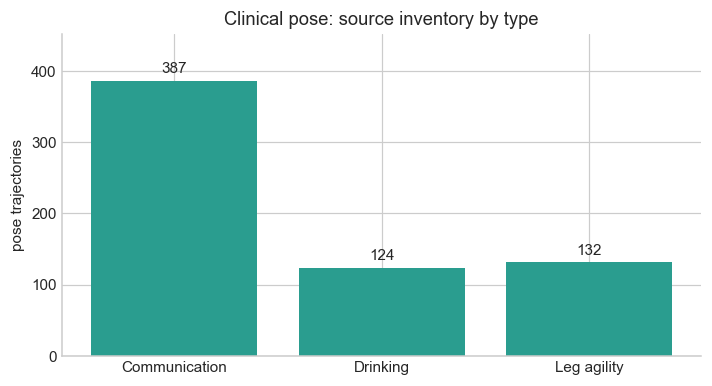

Inventory total: 643 pose trajectories


In [3]:
if KEY == 'MMU':
    counts = pd.Series({k: v for k, v in DATA['score_categories']['MMU folder labels'].items() if v is not None})
    counts.index = ['Normal', 'Mild', 'Moderate', 'Severe']
    unit = 'labeled JSON files'
elif KEY == 'BMCLab':
    counts = pd.Series({'Walking': 887, 'Static': 48})
    unit = 'C3D files'
else:
    counts = pd.Series(DATA['clinical_pose_tasks'])
    unit = 'pose trajectories'
fig, ax = plt.subplots(figsize=(7.5, 3.8))
bars = ax.bar(counts.index, counts.values, color=COLOR)
ax.bar_label(bars, padding=3)
ax.set(ylabel=unit, title=f'{KEY}: source inventory by type')
ax.set_ylim(0, counts.max() * 1.17)
plt.show()
print('Inventory total:', int(counts.sum()), unit)


---
## 4. Recording duration

The associated paper reports 30 FPS capture. Full-archive task medians are shown alongside the three selected example durations. Task durations differ, so the pooled distribution should be interpreted with the task breakdown.


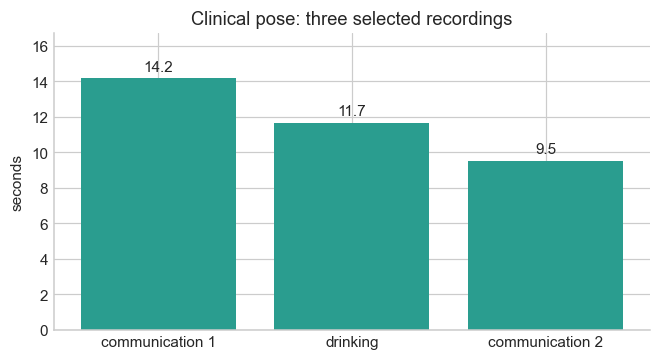

Complete three-task duration summaries:


,task,n,median_s,p90_s,skewness
0,Communication,387,10.87,14.82,0.94
1,Drinking,124,6.95,11.02,1.23
2,Leg agility,132,10.55,15.07,0.41


In [4]:
if KEY == 'MMU':
    lengths = pd.Series([188, 122, 361], index=['selected 1', 'selected 2', 'selected 3'])
    ylabel = 'frames (source FPS unknown)'
else:
    rows = pd.DataFrame(DATA['selected_durations']).query('dataset == @KEY')
    lengths = pd.Series(rows.seconds.values, index=rows['sample'])
    ylabel = 'seconds'
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.bar(lengths.index, lengths.values, color=COLOR)
ax.bar_label(bars, fmt='%.1f' if KEY != 'MMU' else '%d', padding=3)
ax.set(ylabel=ylabel, title=f'{KEY}: three selected recordings')
ax.set_ylim(0, lengths.max() * 1.18)
plt.show()
if KEY == 'Clinical pose':
    print('Complete three-task duration summaries:')
    display(pd.DataFrame(DATA['pose_duration_by_task']).round(2))


---
## 5. Score or source-label distribution

The released UPDRS **gait item 3.10** is averaged across raters and can be fractional. The chart keeps exact zero separate and bins positive values as category *k* = `(k−1, k]`. These are presentation bins, not original integer ratings. The separate **UPDRS Total** has its own median and skewness below.


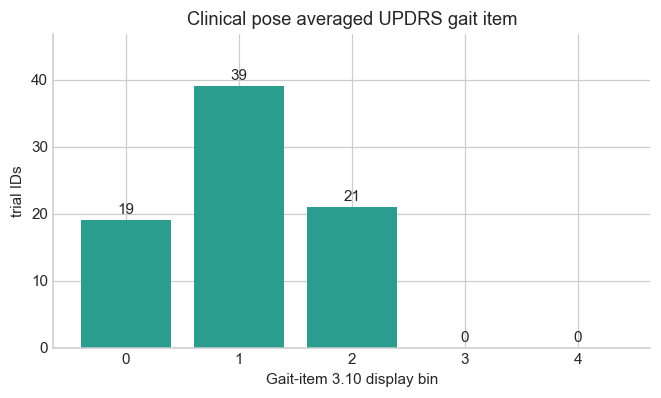

,count
0,19
1,39
2,21
3,0
4,0


In [5]:
if KEY == 'MMU':
    score = pd.Series(DATA['score_categories']['MMU folder labels']).dropna().astype(int)
    score.index = ['1 Normal', '2 Mild', '3 Moderate', '4 Severe']
    fig, ax = plt.subplots(figsize=(7, 3.7))
    bars = ax.bar(score.index, score.values, color=COLOR)
    ax.set(ylabel='JSON recordings', title='MMU source folder labels (not UPDRS)')
elif KEY == 'BMCLab':
    score = pd.DataFrame({'ON': DATA['score_categories']['BMCLab ON walking item'],
                          'OFF': DATA['score_categories']['BMCLab OFF walking item']}).astype(int)
    fig, ax = plt.subplots(figsize=(7, 3.7))
    score.plot.bar(ax=ax, color=['#2a9d8f', '#e08035'], width=0.75)
    bars = ax.containers
    ax.set(xlabel='UPDRS-III walking item', ylabel='participants', title='BMCLab source walking-item ratings')
else:
    score = pd.Series(DATA['score_categories']['Clinical pose gait item bins']).astype(int)
    fig, ax = plt.subplots(figsize=(7, 3.7))
    bars = ax.bar(score.index, score.values, color=COLOR)
    ax.set(xlabel='Gait-item 3.10 display bin', ylabel='trial IDs', title='Clinical pose averaged UPDRS gait item')
for container in ([bars] if KEY != 'BMCLab' else bars):
    ax.bar_label(container, padding=2)
ax.set_ylim(0, (score.values.max() if KEY != 'BMCLab' else score.to_numpy().max()) * 1.2)
plt.show()
display(score.to_frame('count') if KEY != 'BMCLab' else score)


### UPDRS total scores, when available

UPDRS-III Total and gait item are separate fields. A total score is not converted into categories 1–4 without a validated threshold. Skewness is the adjusted Fisher–Pearson sample statistic from the original numeric rows.


,field,unit,n,median,skewness
2,UPDRS Total,trial IDs,79,21.33,1.01
3,UPDRS gait item 3.10,trial IDs,79,0.67,0.59


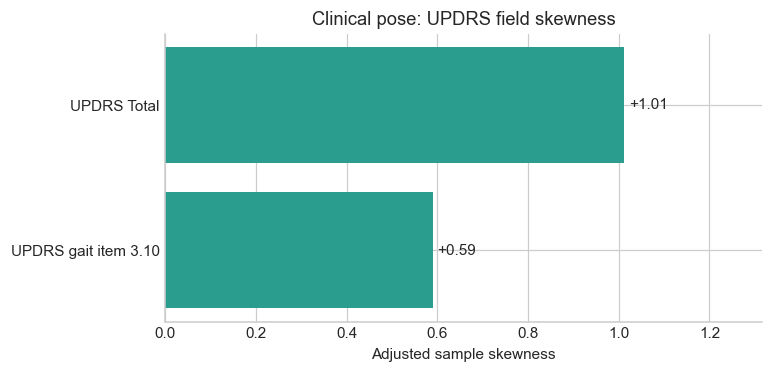

In [6]:
updrs = pd.DataFrame(DATA['updrs_summary'])
updrs = updrs[updrs.dataset == KEY].drop(columns='dataset')
if updrs.empty:
    print('No verified numeric UPDRS score is available for MMU in the inspected JSON.')
else:
    display(updrs.round({'median': 2, 'skewness': 2}))
    fig, ax = plt.subplots(figsize=(7, 3.4))
    bars = ax.barh(updrs.field, updrs.skewness, color=COLOR)
    ax.bar_label(bars, fmt='%+.2f', padding=3)
    ax.invert_yaxis()
    ax.set(xlabel='Adjusted sample skewness', title=f'{KEY}: UPDRS field skewness')
    ax.set_xlim(0, updrs.skewness.max() * 1.3)
    plt.show()


---
## 6. Medication status and clinical context

Trial-linked UDysRS and CAPSIT fields are available in the source, but the plotted gait-item bins and Total summaries are specifically UPDRS. Medication ON/OFF is not an equivalent per-file condition in this inspected archive. Toe tapping is optical flow and is not included in the 643 full-body pose count.


In [7]:
if KEY == 'BMCLab':
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
    for ax, counts, title, ylabel in [
        (axes[0], DATA['medication_file_counts'], 'ON/OFF source files', 'C3D files'),
        (axes[1], DATA['fog_group_participants'], 'Participant FoG groups', 'participants')]:
        bars = ax.bar(list(counts), list(counts.values()), color=COLOR)
        ax.bar_label(bars, padding=3)
        ax.set(title=title, ylabel=ylabel)
        ax.set_ylim(0, max(counts.values()) * 1.2)
    plt.show()
elif KEY == 'Clinical pose':
    display(pd.Series(DATA['clinical_pose_tasks'], name='pose trajectories').to_frame())
    print('UPDRS, UDysRS and CAPSIT annotations are trial linked; toe tapping uses optical flow.')
else:
    print('Four folder labels are available. No source-confirmed medication or numeric UPDRS field is present.')


,pose trajectories
Communication,387
Drinking,124
Leg agility,132


UPDRS, UDysRS and CAPSIT annotations are trial linked; toe tapping uses optical flow.


---
## 7. Data quality and missing movement points

CPM confidence is used to mask uncertain 2D points. The mean valid-body-point fraction across the three selected trajectories is 97.6%; one selected drinking recording is lower at 92.8%. These checks do not validate every released trajectory.


,selected recordings,source frames,mean valid-joint fraction,minimum valid-joint fraction,frame gaps
0,3,1061,0.976,0.928,0


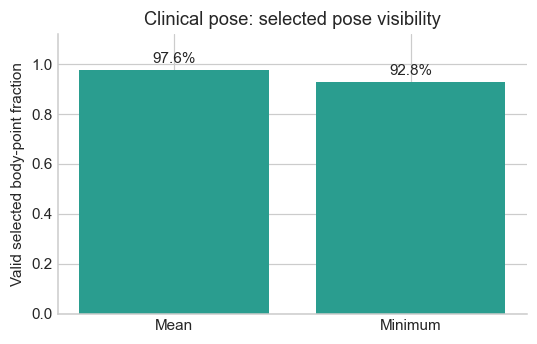

In [8]:
q = DATA['selected_quality'][KEY]
display(pd.DataFrame([{
    'selected recordings': q['selected_recordings'],
    'source frames': q['source_frames'],
    'mean valid-joint fraction': q['mean_valid_joint_fraction'],
    'minimum valid-joint fraction': q['minimum_valid_joint_fraction'],
    'frame gaps': q['frame_gaps'],
}]).round(3))
fig, ax = plt.subplots(figsize=(5.5, 3.3))
vals = [q['mean_valid_joint_fraction'], q['minimum_valid_joint_fraction']]
bars = ax.bar(['Mean', 'Minimum'], vals, color=COLOR)
ax.bar_label(bars, fmt='%.1f%%', labels=[f'{v:.1%}' for v in vals], padding=3)
ax.set(ylim=(0, 1.12), ylabel='Valid selected body-point fraction', title=f'{KEY}: selected pose visibility')
plt.show()


---
## 8. Visualising individual movement

Motion plots are in camera pixels and use the reported 30 FPS. Communication and drinking include seated upper-body movement; pixel displacement depends on viewpoint and is not a physical gait-speed measure.

The local source notebook generates the trajectory, confidence or missing-marker, and elbow-angle plots from actual coordinates. They appear below if present. The public version shows the source-backed summaries above and below without exposing individual movement.


In [9]:
for suffix, title in [('movement', 'Joint trajectory and displacement'),
                      ('missing_confidence', 'Missing joints or confidence'),
                      ('elbow_angles', 'Selected elbow motion')]:
    path = ROOT / 'outputs' / 'figures' / f'{SLUG}_{suffix}.png'
    print(title)
    if path.exists():
        display(Image(filename=str(path), width=850))
    else:
        print('Local figure unavailable; run the detailed source notebook.')
q = DATA['selected_quality'][KEY]
print('Median of the three selected recording-median pelvis rates:',
      q['median_of_recording_median_rates'], q['rate_unit'])


Joint trajectory and displacement
Local figure unavailable; run the detailed source notebook.
Missing joints or confidence
Local figure unavailable; run the detailed source notebook.
Selected elbow motion
Local figure unavailable; run the detailed source notebook.
Median of the three selected recording-median pelvis rates: 15.270092 pixels per second


---
## 9. Distribution skewness

Trajectory duration skewness is +0.58 across 643 entries; it differs by task. Released UPDRS Total skewness is +1.01 across 79 trial IDs; gait item 3.10 skewness is +0.59 across the same 79 IDs. Trial IDs may repeat a participant.


,measure,n,skewness,scope
4,trajectory duration,643,0.58,three tasks pooled
5,UPDRS Total,79,1.01,trial IDs
6,UPDRS gait item 3.10,79,0.59,trial IDs


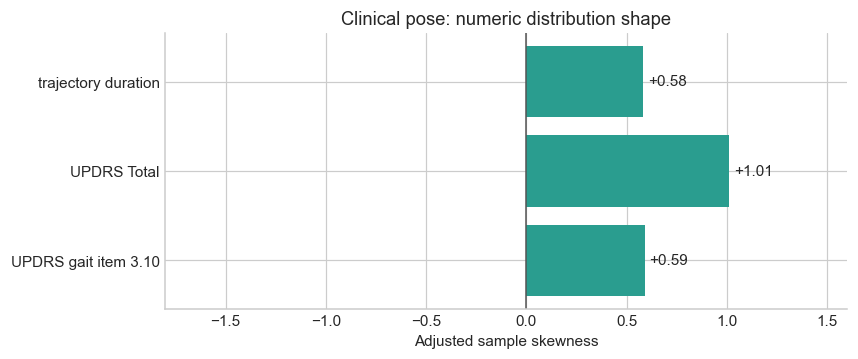

In [10]:
skew = pd.DataFrame(DATA['skewness']).query('dataset == @KEY').drop(columns='dataset')
display(skew.round({'skewness': 2}))
fig, ax = plt.subplots(figsize=(8, max(3.2, len(skew) * 0.75 + 1)))
bars = ax.barh(skew.measure, skew.skewness, color=COLOR)
ax.bar_label(bars, fmt='%+.2f', padding=3)
ax.axvline(0, color='#555', linewidth=1)
ax.invert_yaxis()
ax.set(xlabel='Adjusted sample skewness', title=f'{KEY}: numeric distribution shape')
ax.set_xlim(min(-1.8, skew.skewness.min() * 1.2), max(1.6, skew.skewness.max() * 1.25))
plt.show()


---
## 10. Animated human movement

The three clips use authentic poses or marker trajectories from the selected source recordings. Playback video is an analysis visualization, not original camera video. Local previews and MP4s are displayed when the detailed source notebook has generated them. They are intentionally absent from the public repository.


In [11]:
preview = ROOT / 'outputs' / 'figures' / f'{SLUG}_static_skeletons.png'
if preview.exists():
    display(Image(filename=str(preview), width=900))
else:
    print('Local static skeleton gallery unavailable.')
for i in range(1, 4):
    video = ROOT / 'outputs' / 'videos' / SLUG / f'{SLUG}_{i:02d}.mp4'
    print(f'Selected recording {i}')
    if video.exists():
        display(Video(str(video), embed=True, width=540))
    else:
        print('Local MP4 unavailable; run the detailed source notebook.')


Local static skeleton gallery unavailable.
Selected recording 1
Local MP4 unavailable; run the detailed source notebook.
Selected recording 2
Local MP4 unavailable; run the detailed source notebook.
Selected recording 3
Local MP4 unavailable; run the detailed source notebook.


---
## 11. Full 3D body mesh

These are 2D pose estimates. Without source images, depth calibration, and an independently validated 3D model, a full body surface would be inferred rather than measured. The animation therefore displays the released 2D skeleton.


---
## 12. Final summary

Use this source for task-linked clinical pose analysis and score-distribution work. Distinguish trial IDs from subjects, preserve fractional ratings, and resolve original video access before an image-based VLM study.

**Evidence to present:** inventory chart, correctly named score field and observation unit, numeric skewness with its sample size, selected motion quality, then the three source animations. The detailed reproducible analysis is in [`eda_parkinsons_pose.ipynb`](eda_parkinsons_pose.ipynb); the [comparison report](../docs/dataset_comparison.md) records provenance and limitations.

**Source:** [Official pose repository](https://github.com/limi44/Parkinson-s-Pose-Estimation-Dataset).
